
# Case Study Data Exploration & Insight

**Level:** Beginner to Middle  
**Tools:** Python, Matplotlib, Seaborn  

---
## Assignment Objectives
1. Mampu melakukan Data Understanding dan ekstraksi data secara terstruktur.
2. Mampu merumuskan pertanyaan analisis (Hipotesis/Pertanyaan Bisnis) sebelum membedah data.
3. Mampu melakukan Exploratory Data Analysis (EDA) menggunakan statistika deskriptif.
4. Mampu memilih jenis visualisasi yang tepat (bivariat, distribusi, kategorikal) untuk menjawab pertanyaan spesifik.
5. Mampu mengekstrak Insight (informasi bermakna) dari grafik dan merumuskan kesimpulan.


In [ ]:

# Setup & Library Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)



## Dataset Loading

Use **Seaborn built-in datasets**.  
You may use one or more datasets below:

- tips
- penguins
- flights

Example loading:
```python
df = sns.load_dataset("tips")
```


In [ ]:
# TODO:
# 1. Muat setidaknya SATU dataset menggunakan sns.load_dataset()
# 2. Simpan ke dalam variabel `df`

# Contoh:
# df = sns.load_dataset("tips")
# df.head()


df = sns.load_dataset("tips")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


[link text](https://)
## Pemahaman & Persiapan Data (Data Understanding & Preparation)

### Goal
Memahami struktur data, tipe data, dan mendeteksi anomali atau nilai yang hilang (missing values) sebelum melakukan analisis.


In [ ]:
# TODO:
# 1. Tampilkan 5 baris pertama dari dataset menggunakan .head()
# 2. Periksa tipe data dan jumlah nilai non-null menggunakan .info()
# 3. Periksa nilai yang hilang (missing values) menggunakan .isnull().sum()
# 4. Tampilkan statistika deskriptif dasar untuk kolom numerik menggunakan .describe()

# Tulis kode Anda di bawah ini:

# Menampilkan 5 baris pertama
display(df.head())

# Melihat struktur data dan tipe data
df.info()

# Mengecek missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistik deskriptif variabel numerik
print("\nStatistik Deskriptif:")
display(df.describe())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Missing Values:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

Statistik Deskriptif:


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000



### Questions
1. Berapa banyak kolom numerik dan kategorikal yang terdapat dalam dataset yang Anda pilih?

2. Apakah terdapat nilai yang hilang (missing values) atau anomali pada data? Jika ada, bagaimana strategi Anda untuk menanganinya?

#Jawaban
1. Dataset tips memiliki 7 kolom, yang terdiri dari 3 kolom numerik (total_bill, tip, size) dan 4 kolom kategorikal (sex, smoker, day, time).

2. Hasil pengecekan menggunakan df.isnull().sum(), tidak terdapat missing values pada dataset. Untuk anomali atau outlier, diperlukan pemeriksaan lebih lanjut menggunakan statistik deskriptif dan visualisasi. Jika ditemukan outlier, akan dilakukan evaluasi terlebih dahulu untuk menentukan apakah nilai tersebut valid atau merupakan kesalahan data.



## Task 2 — Pertanyaan Bisnis & Exploratory Data Analysis (EDA)

### Goal
Merumuskan pertanyaan bisnis yang ingin dijawab dan menggunakan statistika deskriptif (groupby/agregasi) untuk menemukan pola awal.


In [ ]:
# TODO:
# 1. Tulis 2-3 pertanyaan analisis/pertanyaan bisnis di sel markdown (di bawah sel ini).
# 2. Gunakan Pandas (seperti .groupby(), .agg(), atau .value_counts()) untuk mengeksplorasi data
#    dan mencari jawaban awal atas pertanyaan tersebut dalam bentuk angka.

# Pertanyaan Bisnis:

# 1. Pada hari apa yang memiliki rata-rata total bill tertinggi?
# 2. Pada waktu makan (Lunch atau Dinner) mana pelanggan memberikan rata-rata tip yang lebih tinggi?
# 3. Apakah terdapat hubungan antara total bill dan tip yang diberikan pelanggan?
# 4. Apakah pelanggan yang merokok (smoker) memiliki rata-rata total_bill yang berbeda dibandingkan pelanggan yang tidak merokok?
# 5. Bagaimana perbedaan rata-rata total_bill berdasarkan jumlah pelanggan (size)?

# Tulis kode Anda di bawah ini:

# 1. Rata-rata total bill berdasarkan hari
avg_bill_by_day = (df.groupby('day', observed=True)['total_bill'].mean().sort_values(ascending=False))

print("Rata-rata Total Bill berdasarkan Hari:")
display(avg_bill_by_day)


# 2. Rata-rata tip berdasarkan waktu makan
avg_tip_by_time = (df.groupby('time', observed=True)['tip'].mean().sort_values(ascending=False))

print("\nRata-rata Tip berdasarkan Waktu Makan:")
display(avg_tip_by_time)


# 3. Korelasi antara total bill dan tip
correlation = df[['total_bill', 'tip']].corr()

print("\nKorelasi antara Total Bill dan Tip:")
display(correlation)

# 4. Rata-rata total bill berdasarkan status smoker
avg_bill_by_smoker = (df.groupby('smoker', observed=True)['total_bill'].mean().sort_values(ascending=False))

print("Rata-rata Total Bill berdasarkan Status Smoker:")
display(avg_bill_by_smoker)

# 5. Rata-rata total bill berdasarkan jumlah pelanggan
avg_bill_by_size = (df.groupby('size', observed=True)['total_bill'].mean().sort_values(ascending=False))

print("\nRata-rata Total Bill berdasarkan Jumlah Pelanggan:")
display(avg_bill_by_size)

Rata-rata Total Bill berdasarkan Hari:


,total_bill
day,
Sun,21.410000
Sat,20.441379
Thur,17.682742
Fri,17.151579



Rata-rata Tip berdasarkan Waktu Makan:


,tip
time,
Dinner,3.102670
Lunch,2.728088



Korelasi antara Total Bill dan Tip:


,total_bill,tip
total_bill,1.000000,0.675734
tip,0.675734,1.000000


Rata-rata Total Bill berdasarkan Status Smoker:


,total_bill
smoker,
Yes,20.756344
No,19.188278



Rata-rata Total Bill berdasarkan Jumlah Pelanggan:


,total_bill
size,
6,34.830000
5,30.068000
4,28.613514
3,23.277632
2,16.448013
1,7.242500


###Question

1. Pada hari apa yang memiliki rata-rata total bill tertinggi?

2. Pada waktu makan (Lunch atau Dinner) mana pelanggan memberikan rata-rata tip yang lebih tinggi?

3. Apakah terdapat hubungan antara total bill dan tip yang diberikan pelanggan?

4. Apakah pelanggan yang merokok (smoker) memiliki rata-rata total_bill yang berbeda dibandingkan pelanggan yang tidak merokok?

5. Bagaimana perbedaan rata-rata total_bill berdasarkan jumlah pelanggan (size)?


**Questions**
1. Mengapa Anda memilih pertanyaan-pertanyaan bisnis di atas?
2. Pola menarik apa yang Anda temukan dari hasil agregasi data (statistika deskriptif) yang baru saja Anda buat?

**Jawaban**

1. Saya memilih pertanyaan-pertanyaan bisnis tersebut karena dapat memberikan gambaran mengenai karakteristik dan pola transaksi pelanggan dari beberapa aspek, yaitu perbedaan rata-rata total_bill berdasarkan hari, waktu makan, status smoker, dan jumlah pelanggan dalam satu transaksi. Selain itu, saya juga ingin mengetahui hubungan antara total_bill dan tip.

2. Berdasarkan hasil agregasi,  menunjukkan bahwa **Sunday memiliki rata-rata `total_bill` tertinggi sebesar 21,41**, sedangkan **Dinner memiliki rata-rata `tip` lebih tinggi sebesar 3,10** dibandingkan Lunch sebesar 2,73. Terdapat **korelasi positif sebesar 0,676 antara `total_bill` dan `tip`**. Pelanggan yang merokok memiliki rata-rata `total_bill` sebesar **20,76**, lebih tinggi dibandingkan non-smoker sebesar 19,19. Selain itu, rata-rata `total_bill` **cenderung meningkat seiring bertambahnya jumlah pelanggan (`size`)**.


## Task 3 — Visualisasi Data (Bivariat, Distribusi, Kategorikal)

### Goal
Membuat visualisasi data yang tepat untuk menjawab Pertanyaan Bisnis yang telah dirumuskan di Task 2.


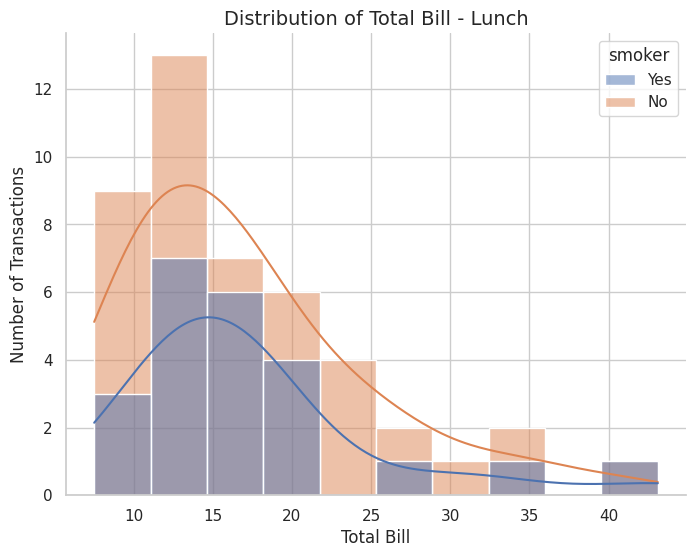

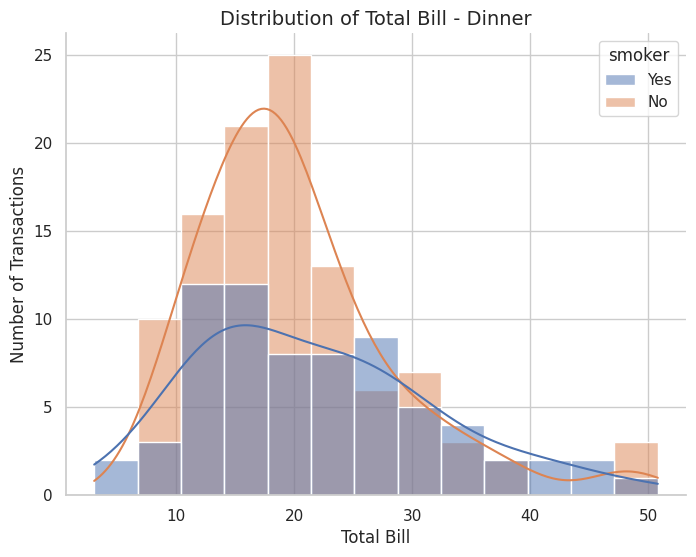

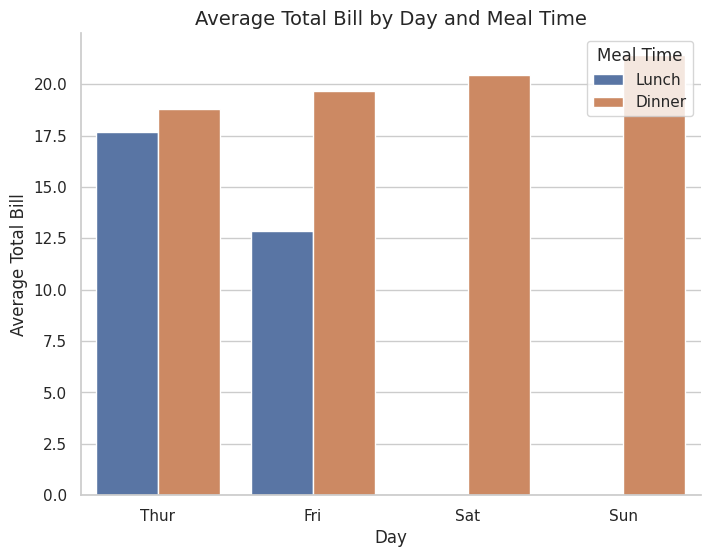

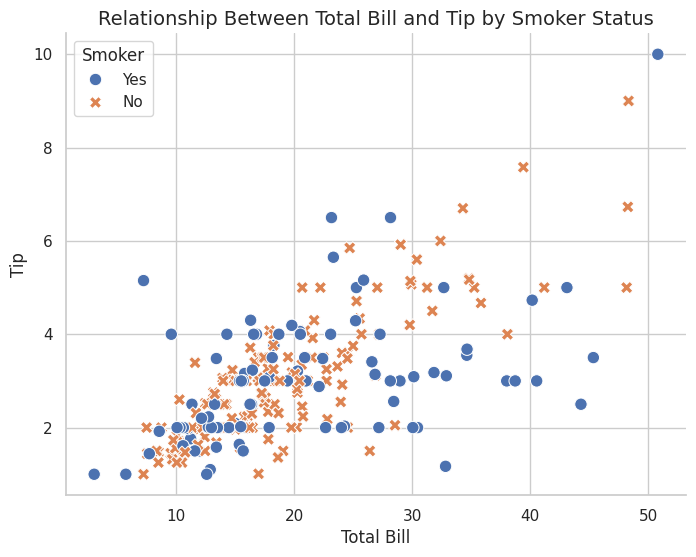

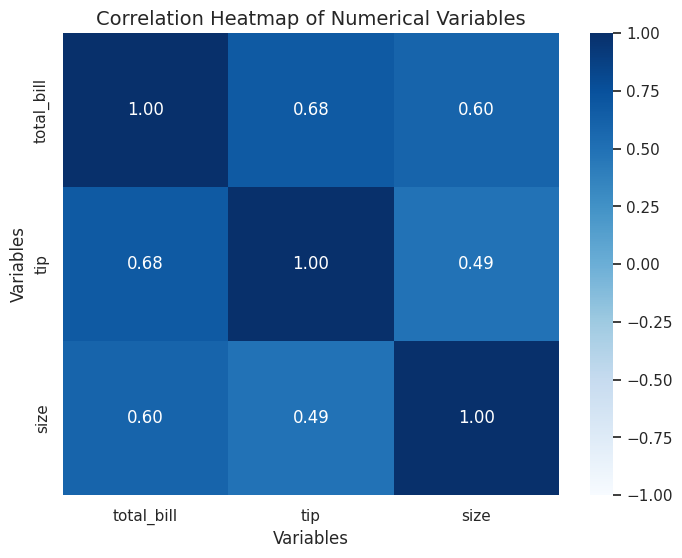

In [ ]:
# TODO:
# Buat minimal 3 visualisasi data berdasarkan pertanyaan Anda:
# 1. Visualisasi distribusi data (contoh: Histogram / KDE / Boxplot)
# 2. Visualisasi data kategorikal (contoh: Bar Chart / Countplot / Pie Chart)
# 3. Visualisasi data bivariat (contoh: Scatterplot / Line plot)
#
# Pastikan setiap grafik memiliki:
# - Judul (Title) yang jelas
# - Label sumbu X & Y (X-axis & Y-axis labels)
# - Keterbacaan warna yang baik (gunakan palet Seaborn/Matplotlib yang sesuai)

# Tulis kode Anda di bawah ini:

# Visualisasi Distribusi
## Luchn
palette = sns.color_palette("deep")
plt.figure(figsize=(8, 6))

sns.histplot(data=df[df['time'] == 'Lunch'],x='total_bill',hue='smoker',kde=True,multiple='layer')

plt.title('Distribution of Total Bill - Lunch', fontsize=14)
plt.xlabel('Total Bill')
plt.ylabel('Number of Transactions')

sns.despine()
plt.show()

## Dinner
palette = sns.color_palette("deep")
plt.figure(figsize=(8, 6))

sns.histplot(data=df[df['time'] == 'Dinner'],x='total_bill',hue='smoker',kde=True,multiple='layer')

plt.title('Distribution of Total Bill - Dinner', fontsize=14)
plt.xlabel('Total Bill')
plt.ylabel('Number of Transactions')

sns.despine()
plt.show()

# Visualisasi Kategorikal
palette = sns.color_palette("deep")
plt.figure(figsize=(8, 6))

sns.barplot(data=df,x='day',y='total_bill',hue='time',errorbar=None)

plt.title('Average Total Bill by Day and Meal Time', fontsize=14)
plt.xlabel('Day')
plt.ylabel('Average Total Bill')
plt.legend(title='Meal Time')

sns.despine()
plt.show()

# Visualisasi Bivariate
palette = sns.color_palette("deep")
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df,x='total_bill',y='tip',hue='smoker',style='smoker',s=80)

plt.title('Relationship Between Total Bill and Tip by Smoker Status', fontsize=14)
plt.xlabel('Total Bill')
plt.ylabel('Tip')
plt.legend(title='Smoker')

sns.despine()
plt.show()

# Heatmap Korelasi Variabel Numerik
plt.figure(figsize=(8, 6))

corr = df[['total_bill', 'tip', 'size']].corr()

sns.heatmap(corr,annot=True,fmt='.2f',cmap='Blues',vmin=-1,vmax=1)

plt.title('Correlation Heatmap of Numerical Variables', fontsize=14)
plt.xlabel('Variables')
plt.ylabel('Variables')

plt.show()


### Questions
1. Mengapa Anda memilih jenis grafik tertentu untuk masing-masing visualisasi (misal, mengapa menggunakan histogram untuk data A, dan scatterplot untuk melihat hubungan B dan C)?
2. Apakah terdapat informasi yang lebih jelas saat divisualisasikan dibandingkan saat hanya melihat angka agregasi di Task 2?

### Jawaban
1. Saya memilih jenis visualisasi berdasarkan karakteristik variabel dan tujuan analisis. Histogram digunakan untuk melihat distribusi `total_bill` berdasarkan `smoker` dan `time`, barplot digunakan untuk membandingkan rata-rata `total_bill` berdasarkan `day` dan `time`, sedangkan scatterplot digunakan untuk melihat hubungan `total_bill` dan `tip` berdasarkan status `smoker`. Heatmap digunakan sebagai visualisasi tambahan untuk melihat korelasi antar variabel numerik.

2. Ya. Visualisasi memberikan insight tambahan karena dapat memperlihatkan pola dan perbedaan antar kelompok secara lebih jelas. Selain hubungan antara `total_bill` dan `tip`, visualisasi juga menunjukkan perbedaan transaksi berdasarkan hari, waktu makan, dan status `smoker`.



## Task 4 — Ekstraksi Insight & Kesimpulan

### Goal
Menarik kesimpulan bermakna berdasarkan visualisasi yang telah dibuat.


In [ ]:
# TODO (Jawab dalam bentuk teks Markdown):
# Tuliskan 3 Insights (temuan penting) berdasarkan grafik yang telah Anda buat di Task 3.
# Tuliskan 1 Kesimpulan utama (Overall Conclusion) dari keseluruhan dataset yang Anda analisis.

**Insights:**
1. ...
2. ...
3. ...

**Kesimpulan Utama (Overall Conclusion):**
...

SyntaxError: invalid syntax (3335636986.py, line 5)

**Insights:**
## Task 4: Insight & Conclusion

**Insights:**

1. Rata-rata `total_bill` berbeda berdasarkan hari, dengan **Sunday memiliki rata-rata tertinggi sebesar 21,41**, sedangkan **Friday memiliki rata-rata terendah sebesar 17,15**. Selain itu, rata-rata `tip` pada **Dinner sebesar 3,10**, lebih tinggi dibandingkan **Lunch sebesar 2,73**.

2. Terdapat **hubungan positif antara `total_bill` dan `tip`**, dengan nilai korelasi sebesar **0,676**. Hal ini menunjukkan bahwa transaksi dengan `total_bill` yang lebih tinggi cenderung memiliki `tip` yang lebih tinggi, meskipun hubungan tersebut tidak bersifat sempurna.

3. Pelanggan yang merokok memiliki rata-rata `total_bill` sebesar **20,76**, lebih tinggi dibandingkan pelanggan yang tidak merokok sebesar **19,19**. Selain itu, rata-rata `total_bill` cenderung meningkat seiring bertambahnya jumlah pelanggan, dari **7,24 pada size 1** menjadi **34,83 pada size 6**.



**Kesimpulan Utama (Overall Conclusion):**
* **Berdasarkan hasil EDA**, Secara keseluruhan, hasil EDA menunjukkan bahwa karakteristik transaksi pada dataset tips berbeda berdasarkan hari, waktu makan, status smoker, dan jumlah pelanggan. Sunday memiliki rata-rata total_bill tertinggi sebesar 21,41, sedangkan Dinner memiliki rata-rata tip lebih tinggi sebesar 3,10 dibandingkan Lunch sebesar 2,73. Selain itu, terdapat hubungan positif antara total_bill dan tip dengan korelasi sebesar 0,676, serta rata-rata total_bill cenderung meningkat seiring bertambahnya jumlah pelanggan.
* **Berdasarkan hasil analisis**, pihak restoran dapat memberikan perhatian lebih pada periode Dinner dan hari dengan rata-rata transaksi yang lebih tinggi, khususnya Sunday. Restoran juga dapat mempertimbangkan strategi untuk meningkatkan nilai transaksi melalui penawaran menu atau paket yang sesuai untuk kelompok pelanggan yang lebih besar, karena rata-rata total_bill cenderung meningkat seiring bertambahnya jumlah pelanggan. Selain itu, hubungan positif antara total_bill dan tip menunjukkan bahwa peningkatan nilai transaksi dapat berjalan seiring dengan peningkatan tip, meskipun hasil ini tidak menunjukkan hubungan sebab-akibat.




## Reflection

Jawab secara singkat:
1. Langkah mana yang memakan waktu paling banyak bagi Anda: Data Understanding, EDA, atau merancang visualisasinya? Mengapa?
2. Jika hasil analisis ini dipresentasikan kepada orang awam (non-technical stakeholders), apa yang akan Anda sederhanakan dari cara penyampaian grafiknya?
3. Sebutkan satu best practice (praktik terbaik) dalam EDA atau Visualisasi Data yang menurut Anda paling penting dan akan terus Anda terapkan ke depannya.


**Jawaban Reflection**
1. Menurut saya adalah merancang visualisasi langkah yang paling memakan waktu, karena perlu memilih jenis grafik yang sesuai dengan tujuan analisis, menentukan judul dan label yang jelas, serta memastikan grafik mudah dipahami.
2. Saya akan menyederhanakan istilah teknis dan lebih menekankan pada informasi utama, seperti tren, perbandingan, dan angka penting. Visualisasi berupa histogram, barplot, dll dibuat sederhana agar pesan utama dapat dipahami dengan cepat.
3. Best practice yang akan terus saya terapkan adalah **memulai analisis dari business question dan memilih visualisasi yang sesuai dengan tujuan analisis**, sehingga hasil yang disampaikan tetap relevan dan mudah dipahami.

